<a href="https://colab.research.google.com/github/lvi8544851094-eng/aiml-30-days/blob/main/day01-02/lab_chandigarh_house_prices.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# @title ▶ Run me first: Chandigarh Tricity listings builder
import numpy as np
import pandas as pd

def build_chandigarh_housing(n=2500, seed=42):
    rng = np.random.default_rng(seed)

    # city, locality, flat / builder-floor / house rate (Rs per sq ft built-up; 0 = type not sold there),
    # km to Sector 17 (city centre), km to Chandigarh airport, share of listings
    L = [
        ("Chandigarh", "Sector 8",          0, 22000, 27000,  2.5, 16, 2),
        ("Chandigarh", "Sector 9",          0, 23000, 28000,  2.0, 16, 2),
        ("Chandigarh", "Sector 10",         0, 21000, 26000,  2.5, 17, 2),
        ("Chandigarh", "Sector 16",         0, 20000, 24000,  1.5, 15, 2),
        ("Chandigarh", "Sector 21",         0, 17000, 22000,  1.5, 13, 3),
        ("Chandigarh", "Sector 27",         0, 16500, 21000,  3.0, 12, 3),
        ("Chandigarh", "Sector 35",         0, 15500, 20000,  2.5, 11, 3),
        ("Chandigarh", "Sector 33",     13500, 14500, 16000,  4.0,  9, 4),
        ("Chandigarh", "Sector 44",     13000, 14000, 15000,  5.0,  9, 4),
        ("Chandigarh", "Sector 46",     12500, 13500, 14500,  6.0,  8, 4),
        ("Chandigarh", "Sector 49",     14000,     0,     0,  7.0,  7, 5),
        ("Chandigarh", "Sector 51",     14500,     0,     0,  8.0,  7, 4),
        ("Chandigarh", "Sector 63",     12000,     0,     0,  9.0,  6, 4),
        ("Chandigarh", "Manimajra",     10500, 11000, 13000,  7.0, 15, 5),
        ("Panchkula",  "Panchkula Sector 9",  13000, 15000, 20000,  9.0, 20, 3),
        ("Panchkula",  "Panchkula Sector 20",  8500,  9000,     0, 12.0, 18, 4),
        ("Panchkula",  "Panchkula Extension",  6500,  6800,  8500, 16.0, 22, 3),
        ("Mohali",     "Mohali Sector 70",    11000, 11500, 14500, 10.0,  9, 4),
        ("Mohali",     "Mohali Sector 82",    10400,  9500,     0, 14.0,  7, 4),
        ("Mohali",     "Mohali Sector 88",     9600,     0,     0, 16.0,  9, 3),
        ("Mohali",     "Aerocity",             8800,  8500, 10000, 15.0,  4, 4),
        ("Mohali",     "Mohali Sector 118",    9500,     0,     0, 18.0, 12, 3),
        ("Zirakpur",   "Zirakpur VIP Road",    6000,  5500,     0, 11.0,  6, 5),
        ("Zirakpur",   "Zirakpur Patiala Road",5200,  5000,     0, 12.0,  8, 4),
        ("Kharar",     "Kharar Sunny Enclave", 4800,  4600,  5500, 18.0, 16, 4),
        ("Kharar",     "Kharar Landran Road",  5300,     0,     0, 17.0, 14, 3),
        ("New Chandigarh", "New Chandigarh (Mullanpur)", 8000, 7500, 9000, 14.0, 25, 4),
    ]
    loc = pd.DataFrame(L, columns=["city", "locality", "r_flat", "r_floor", "r_house",
                                   "dist_c", "dist_a", "w"])
    idx = rng.choice(len(loc), size=n, p=loc.w / loc.w.sum())

    rows = []
    for i in idx:
        r = loc.iloc[i]
        types = [t for t, rate in [("Flat", r.r_flat), ("Builder Floor", r.r_floor),
                                   ("Independent House", r.r_house)] if rate > 0]
        tw = {"Flat": 0.55, "Builder Floor": 0.30, "Independent House": 0.15}
        p = np.array([tw[t] for t in types]); p = p / p.sum()
        ptype = rng.choice(types, p=p)

        if ptype == "Flat":
            bhk = rng.choice([1, 2, 3, 4], p=[0.10, 0.40, 0.40, 0.10])
            area = {1: (500, 750), 2: (850, 1250), 3: (1250, 1900), 4: (1900, 2800)}[bhk]
            rate = r.r_flat
        elif ptype == "Builder Floor":
            bhk = rng.choice([2, 3, 4], p=[0.30, 0.50, 0.20])
            area = {2: (900, 1300), 3: (1300, 2000), 4: (2000, 2800)}[bhk]
            rate = r.r_floor
        else:
            bhk = rng.choice([3, 4, 5, 6], p=[0.25, 0.40, 0.27, 0.08])
            area = {3: (1800, 2800), 4: (2800, 4500), 5: (4500, 7000), 6: (7000, 10000)}[bhk]
            rate = r.r_house
        area_sqft = int(round(rng.uniform(*area), -1))

        bathrooms = int(np.clip(bhk + rng.choice([-1, 0, 0, 1]), 1, bhk + 1))
        age = int(np.clip(rng.gamma(2.0, 5.0), 0, 40))
        if r.city in ("New Chandigarh", "Kharar", "Zirakpur") or r.locality in ("Aerocity", "Mohali Sector 118"):
            age = int(np.clip(age * 0.4, 0, 15))          # newer townships
        furnishing = rng.choice(["Unfurnished", "Semi-Furnished", "Fully Furnished"], p=[0.45, 0.40, 0.15])
        parking = int(rng.choice([0, 1, 2], p=[0.15, 0.55, 0.30]))
        if ptype == "Flat":
            total_floors = int(rng.choice([4, 8, 12, 14, 18, 20]))
            floor = int(rng.integers(0, total_floors + 1))
            gated = int(rng.random() < 0.80)
        else:
            total_floors = 3 if ptype == "Independent House" else int(rng.choice([3, 4]))
            floor = 0 if ptype == "Independent House" else int(rng.integers(0, total_floors))
            gated = int(rng.random() < 0.15)
        park_facing = int(rng.random() < 0.25)
        corner = int(ptype == "Independent House" and rng.random() < 0.20)
        dist_c = round(max(0.5, r.dist_c + rng.normal(0, 0.6)), 1)
        dist_a = round(max(1.0, r.dist_a + rng.normal(0, 0.8)), 1)

        # --- the hidden pricing rule (students never see this) ---
        dep = 0.004 if ptype == "Independent House" else 0.009
        m = max(0.72, 1 - dep * age)
        m *= {"Unfurnished": 1.00, "Semi-Furnished": 1.03, "Fully Furnished": 1.07}[furnishing]
        m *= {0: 0.97, 1: 1.00, 2: 1.03}[parking]
        m *= 1.04 if gated else 1.0
        m *= 1.05 if park_facing else 1.0
        m *= 1.08 if corner else 1.0
        if ptype == "Flat":
            m *= 0.97 if floor == total_floors else (1 + 0.004 * min(floor, 10))
        m *= rng.lognormal(0, 0.10)                       # negotiation / market noise
        price_lakh = round(area_sqft * rate * m / 1e5, 1)

        rows.append([r.city, r.locality, ptype, bhk, area_sqft, bathrooms, floor, total_floors,
                     age, furnishing, parking, gated, park_facing, corner, dist_c, dist_a, price_lakh])

    df = pd.DataFrame(rows, columns=[
        "city", "locality", "property_type", "bhk", "area_sqft", "bathrooms", "floor",
        "total_floors", "age_years", "furnishing", "parking", "gated_society", "park_facing",
        "corner_plot", "dist_city_centre_km", "dist_airport_km", "price_lakh"])

    # --- real-world mess, like data scraped from property portals ---
    df[["age_years", "bathrooms"]] = df[["age_years", "bathrooms"]].astype(float)
    for col, frac in [("age_years", 0.03), ("bathrooms", 0.02), ("furnishing", 0.02)]:
        df.loc[rng.choice(n, int(n * frac), replace=False), col] = np.nan
    bad = rng.choice(n, 6, replace=False)
    df.loc[bad[:3], "price_lakh"] = df.loc[bad[:3], "price_lakh"] * 1e5   # entered in rupees, not lakh
    df.loc[bad[3:], "area_sqft"] = 0                                     # missing area typed as 0
    dupes = df.sample(20, random_state=seed)                             # same listing posted twice
    df = pd.concat([df, dupes]).sample(frac=1, random_state=seed).reset_index(drop=True)
    df.insert(0, "listing_id", [f"CHD-{100001 + i}" for i in range(len(df))])  # reposts get a new id
    return df

print("Builder ready.")

Builder ready.


In [3]:
import glob
import pandas as pd

files = glob.glob("chandigarh_housing.csv") + glob.glob("/kaggle/input/**/chandigarh_housing.csv", recursive=True)

if files:
    df = pd.read_csv(files[0])
    print("Loaded from file:", files[0])
else:
    df = build_chandigarh_housing(n=2500, seed=42)
    df.to_csv("chandigarh_housing.csv", index=False)
    print("Built the dataset and saved chandigarh_housing.csv")

print("Listings:", len(df), "| Columns:", df.shape[1])
df.sample(5, random_state=1)

Built the dataset and saved chandigarh_housing.csv
Listings: 2520 | Columns: 18


,listing_id,city,locality,property_type,bhk,area_sqft,bathrooms,floor,total_floors,age_years,furnishing,parking,gated_society,park_facing,corner_plot,dist_city_centre_km,dist_airport_km,price_lakh
891,CHD-100892,Chandigarh,Sector 21,Builder Floor,2,1280,1.0,3,4,3.0,Unfurnished,0,1,1,0,2.0,13.3,242.9
2384,CHD-102385,Chandigarh,Sector 21,Independent House,3,2010,4.0,0,3,NaN,Unfurnished,2,0,0,0,1.1,13.6,503.6
2096,CHD-102097,Chandigarh,Sector 21,Independent House,4,3510,5.0,0,3,17.0,Semi-Furnished,2,0,0,0,1.8,13.6,779.0
2359,CHD-102360,Mohali,Aerocity,Flat,2,950,2.0,1,14,5.0,Semi-Furnished,1,1,0,0,15.2,5.2,75.9
1370,CHD-101371,Mohali,Mohali Sector 88,Flat,1,730,1.0,0,14,4.0,Fully Furnished,1,1,0,0,15.8,10.1,80.7


In [ ]:
dupes = df.duplicated(subset=df.columns.drop("listing_id"))
print("Same home posted twice      :", dupes.sum())
print("Area typed as 0 sq ft       :", (df["area_sqft"] == 0).sum())
print("Price above ₹100 crore      :", (df["price_lakh"] > 10_000).sum(), f"(biggest: {df['price_lakh'].max():,.0f} lakh)")
print("\nBlank values per column:")
print(df.isna().sum()[lambda s: s > 0])

Same home posted twice      : 20
Area typed as 0 sq ft       : 3
Price above ₹100 crore      : 3 (biggest: 12,680,000 lakh)

Blank values per column:
bathrooms     50
age_years     76
furnishing    51
dtype: int64


In [4]:
rate = df["price_lakh"] * 1e5 / df["area_sqft"]          # ₹ per sq ft (only for looking, not a model input)

summary = (df.assign(rate=rate)
             .groupby("city")
             .agg(listings=("rate", "size"),
                  median_price_lakh=("price_lakh", "median"),
                  median_rate_per_sqft=("rate", "median"))
             .sort_values("median_rate_per_sqft", ascending=False)
             .round(0))
summary

,listings,median_price_lakh,median_rate_per_sqft
city,,,
Chandigarh,1262,222.0,14401.0
Mohali,457,138.0,10024.0
Panchkula,264,131.0,8833.0
New Chandigarh,116,127.0,8219.0
Zirakpur,239,76.0,5767.0
Kharar,182,75.0,5314.0


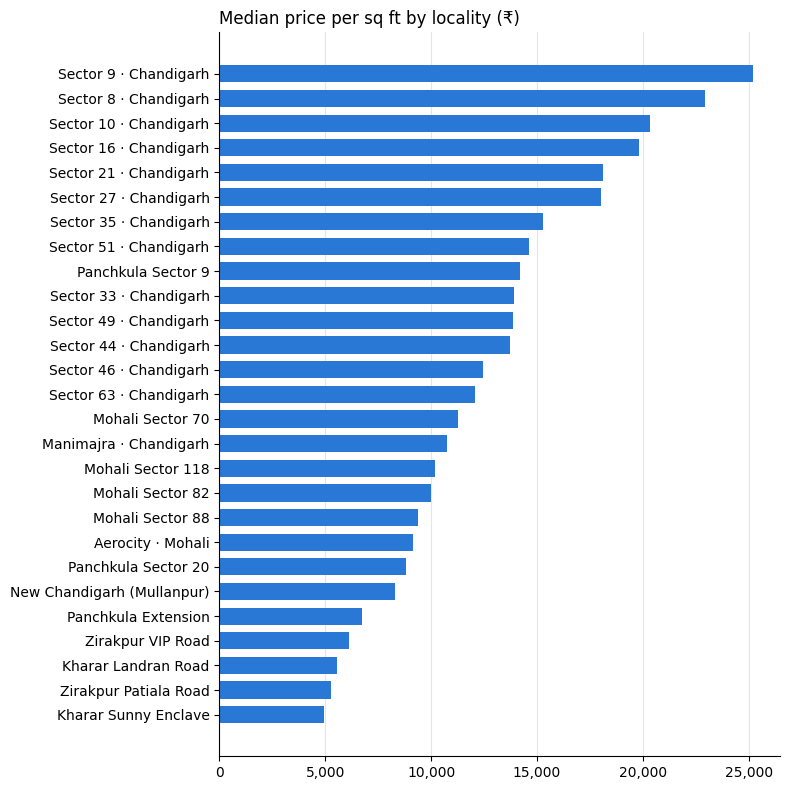

In [ ]:
import matplotlib.pyplot as plt

by_loc = df.assign(rate=rate).groupby(["locality", "city"])["rate"].median().sort_values()
labels = [f"{loc} · {city}" if not loc.startswith(city) else loc for loc, city in by_loc.index]

fig, ax = plt.subplots(figsize=(8, 8))
ax.barh(labels, by_loc.values, color="#2a78d6", height=0.7)
ax.set_title("Median price per sq ft by locality (₹)", loc="left", fontsize=12)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:,.0f}")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e5e5e5")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

In [5]:
import numpy as np
from sklearn.metrics import mean_absolute_error

def report(name, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    pct = np.abs(y_pred - y_true) / y_true
    print(f"{name:<28} avg miss ₹{mean_absolute_error(y_true, y_pred):6.1f} lakh | "
          f"typical miss {np.median(pct):5.1%} | within ±10%: {np.mean(pct <= 0.10):5.1%}")

y = df["price_lakh"]
report("Always guess the median", y, np.full(len(y), y.median()))

Always guess the median      avg miss ₹11207.8 lakh | typical miss 43.6% | within ±10%: 12.3%


In [6]:
RATE_PER_SQFT = {            # <- edit me (₹ per sq ft)
    "Chandigarh":     15000,
    "Panchkula":      10000,
    "Mohali":          9000,
    "New Chandigarh":  8000,
    "Zirakpur":        5500,
    "Kharar":          5000,
}

def thumb_rule(homes):
    return homes["area_sqft"] * homes["city"].map(RATE_PER_SQFT) / 1e5   # in ₹ lakh

df["rule_pred"] = thumb_rule(df)
report("Your thumb rule", df["price_lakh"], df["rule_pred"])

Your thumb rule              avg miss ₹11124.0 lakh | typical miss 15.5% | within ±10%: 33.5%


In [7]:
pd.set_option("display.max_columns", None)
show = ["locality", "property_type", "bhk", "area_sqft", "age_years", "price_lakh", "rule_pred"]
err = (df["rule_pred"] - df["price_lakh"]) / df["price_lakh"]

print("Homes your rule UNDER-priced the most (the seller loses money):")
display(df.loc[err.nsmallest(5).index, show].round(1))
print("Homes your rule OVER-priced the most (the listing sits unsold):")
display(df.loc[err.nlargest(5).index, show].round(1))

Homes your rule UNDER-priced the most (the seller loses money):


,locality,property_type,bhk,area_sqft,age_years,price_lakh,rule_pred
955,Manimajra,Builder Floor,3,0,1.0,134.9,0.0
2227,Panchkula Sector 9,Flat,4,0,11.0,244.6,0.0
2488,Zirakpur Patiala Road,Builder Floor,2,0,2.0,52.0,0.0
528,Mohali Sector 82,Flat,2,950,8.0,10100000.0,85.5
108,Kharar Landran Road,Flat,2,990,8.0,5110000.0,49.5


Homes your rule OVER-priced the most (the listing sits unsold):


,locality,property_type,bhk,area_sqft,age_years,price_lakh,rule_pred
1250,Panchkula Extension,Flat,2,990,28.0,45.5,99.0
1198,Panchkula Extension,Flat,3,1700,15.0,81.9,170.0
240,Sector 63,Flat,3,1380,NaN,100.9,207.0
491,Manimajra,Flat,2,850,28.0,64.7,127.5
223,Panchkula Extension,Builder Floor,2,1030,21.0,52.4,103.0


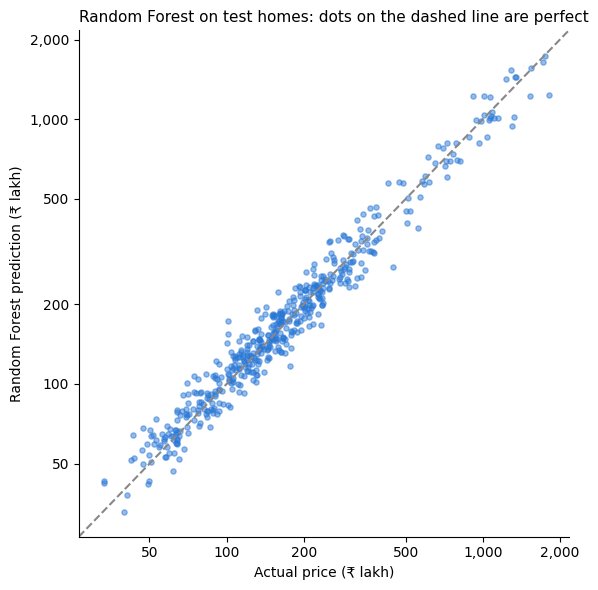

In [ ]:
fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, forest_pred, s=14, alpha=0.5, color="#2a78d6")
lims = [y_test.min() * 0.8, y_test.max() * 1.2]
ax.plot(lims, lims, color="#888888", linewidth=1.5, linestyle="--")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlim(lims); ax.set_ylim(lims)
ticks = [t for t in [25, 50, 100, 200, 500, 1000, 2000] if lims[0] <= t <= lims[1]]
ax.set_xticks(ticks, [f"{t:,}" for t in ticks]); ax.set_yticks(ticks, [f"{t:,}" for t in ticks])
ax.minorticks_off()
ax.set_xlabel("Actual price (₹ lakh)"); ax.set_ylabel("Random Forest prediction (₹ lakh)")
ax.set_title("Random Forest on test homes: dots on the dashed line are perfect", loc="left", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

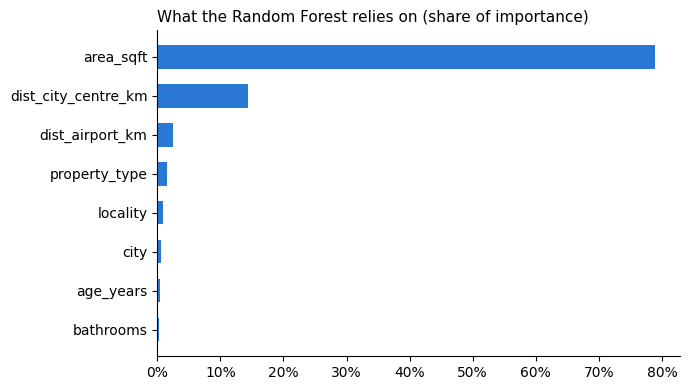

In [ ]:
names = forest.named_steps["columntransformer"].get_feature_names_out()
importance = pd.Series(forest.named_steps["randomforestregressor"].feature_importances_, index=names)

def original_column(name):
    name = name.split("__", 1)[1]
    return next((c for c in text_cols if name.startswith(c + "_")), name)

drivers = importance.groupby(original_column).sum().sort_values()
drivers = drivers[drivers >= 0.002]

fig, ax = plt.subplots(figsize=(7, 4))
ax.barh(drivers.index, drivers.values, color="#2a78d6", height=0.6)
ax.set_title("What the Random Forest relies on (share of importance)", loc="left", fontsize=11)
ax.xaxis.set_major_formatter(lambda x, _: f"{x:.0%}")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [ ]:
lookup = df.groupby("locality").agg(city=("city", "first"),
                                    dist_city_centre_km=("dist_city_centre_km", "median"),
                                    dist_airport_km=("dist_airport_km", "median"))

def make_home(locality, property_type, bhk, area_sqft, age_years=5, city=None,
              dist_city_centre_km=None, dist_airport_km=None, furnishing="Semi-Furnished",
              parking=1, gated_society=0, park_facing=0, corner_plot=0, floor=1, total_floors=4):
    known = locality in lookup.index
    return dict(
        city=city or lookup.loc[locality, "city"], locality=locality, property_type=property_type,
        bhk=bhk, area_sqft=area_sqft, bathrooms=bhk, floor=floor, total_floors=total_floors,
        age_years=age_years, furnishing=furnishing, parking=parking, gated_society=gated_society,
        park_facing=park_facing, corner_plot=corner_plot,
        dist_city_centre_km=dist_city_centre_km if not known else lookup.loc[locality, "dist_city_centre_km"],
        dist_airport_km=dist_airport_km if not known else lookup.loc[locality, "dist_airport_km"])

homes = pd.DataFrame([
    make_home("Kharar Sunny Enclave", "Flat", 2, 1000, age_years=3, gated_society=1, floor=4, total_floors=12),
    make_home("Aerocity", "Flat", 3, 1500, age_years=2, gated_society=1, floor=7, total_floors=14),
    make_home("Sector 44", "Builder Floor", 3, 1600, age_years=15),
    make_home("Sector 10", "Independent House", 5, 6500, age_years=20, parking=2),
    make_home("Mohali Sector 99", "Flat", 3, 1400, city="Mohali",           # not in our data!
              dist_city_centre_km=17, dist_airport_km=8, gated_society=1),
    make_home("Sector 9", "Independent House", 8, 20000, age_years=10),     # a palace
    # add your own here
], columns=X.columns)

homes["thumb_rule_lakh"] = thumb_rule(homes).round(1)
homes["forest_lakh"] = forest.predict(homes[X.columns]).round(1)
homes[["locality", "property_type", "bhk", "area_sqft", "thumb_rule_lakh", "forest_lakh"]]

,locality,property_type,bhk,area_sqft,thumb_rule_lakh,forest_lakh
0,Kharar Sunny Enclave,Flat,2,1000,50.0,49.6
1,Aerocity,Flat,3,1500,135.0,138.9
2,Sector 44,Builder Floor,3,1600,240.0,208.4
3,Sector 10,Independent House,5,6500,975.0,1597.7
4,Mohali Sector 99,Flat,3,1400,126.0,133.1
5,Sector 9,Independent House,8,20000,3000.0,2518.1


In [ ]:
# @title 🏠 Price my home
locality = "Sector 27"  # @param ["Sector 8", "Sector 9", "Sector 10", "Sector 16", "Sector 21", "Sector 27", "Sector 35", "Sector 33", "Sector 44", "Sector 46", "Sector 49", "Sector 51", "Sector 63", "Manimajra", "Panchkula Sector 9", "Panchkula Sector 20", "Panchkula Extension", "Mohali Sector 70", "Mohali Sector 82", "Mohali Sector 88", "Aerocity", "Mohali Sector 118", "Zirakpur VIP Road", "Zirakpur Patiala Road", "Kharar Sunny Enclave", "Kharar Landran Road", "New Chandigarh (Mullanpur)"]
property_type = "Independent House"  # @param ["Flat", "Builder Floor", "Independent House"]
bhk = 3  # @param {type:"slider", min:1, max:6, step:1}
area_sqft = 1500  # @param {type:"integer"}
age_years = 3  # @param {type:"slider", min:0, max:40, step:1}
furnishing = "Fully Furnished"  # @param ["Unfurnished", "Semi-Furnished", "Fully Furnished"]
parking = "0"  # @param [0, 1, 2]
gated_society = False  # @param {type:"boolean"}
park_facing = False  # @param {type:"boolean"}

mine = pd.DataFrame([make_home(locality, property_type, bhk, area_sqft, age_years=age_years,
                               furnishing=furnishing, parking=int(parking),
                               gated_society=int(gated_society), park_facing=int(park_facing))],
                    columns=X.columns)
ml_price = forest.predict(mine)[0]
rule_price = thumb_rule(mine).iloc[0]
print(f"{bhk}BHK {property_type.lower()} in {locality}, {area_sqft:,} sq ft")
print(f"  Random Forest estimate : ₹{ml_price:,.1f} lakh  (₹{ml_price * 1e5 / area_sqft:,.0f} per sq ft)")
print(f"  Your thumb rule        : ₹{rule_price:,.1f} lakh")

3BHK independent house in Sector 27, 1,500 sq ft
  Random Forest estimate : ₹339.1 lakh  (₹22,609 per sq ft)
  Your thumb rule        : ₹225.0 lakh
